In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. Parameters
tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]
equal_weight = 1 / len(tickers)

In [3]:
# 2. Download Adjusted Close Data
data = yf.download(tickers, period="10y", interval="1d", auto_adjust=False)["Adj Close"]
data = data.dropna()  # Drop rows with missing data
# Resample (WEEKLY)
data_resampled = data.resample("W-FRI").last()

[*********************100%***********************]  7 of 7 completed


In [4]:
# 3. Normalize prices (X(t) / X(0))
normalized = data_resampled / data_resampled.iloc[0]

In [5]:
# 4. BAH (Buy-And-Hold) Portfolio 
# Fixed allocation from t=0 (just scales each column by 1/7 and sums)
bah_portfolio = (normalized * equal_weight).sum(axis=1) 

In [6]:
# 5. Constantly Rebalanced Portfolio
# Compute weekly returns
weekly_returns = data_resampled.pct_change().dropna()

In [7]:
# Create a list of rebalanced returns and start at V_0
rebalanced_values = [10_000]  

In [8]:
# Rebalance to equal weights weekly
for t in range(1, len(weekly_returns)): 
    step_growth = (equal_weight * weekly_returns.iloc[t]).sum()
    rebalanced_values.append(rebalanced_values[t-1] * (1 + step_growth))

In [12]:
rebalanced_portfolio = pd.Series(rebalanced_values, index=data.index[1:])
print(rebalanced_portfolio.head())
print(rebalanced_portfolio.tail())

ValueError: Length of values (521) does not match length of index (2513)

In [10]:
# 6. Market Index
market_index = data_resampled.sum(axis=1) / data_resampled.sum(axis=1).iloc[0]
print(market_index)

Date
2015-07-03     1.000000
2015-07-10     0.997517
2015-07-17     1.088980
2015-07-24     1.087591
2015-07-31     1.076561
                ...    
2025-05-30     9.763390
2025-06-06     9.894264
2025-06-13     9.950335
2025-06-20     9.929086
2025-06-27    10.347821
Freq: W-FRI, Length: 522, dtype: float64


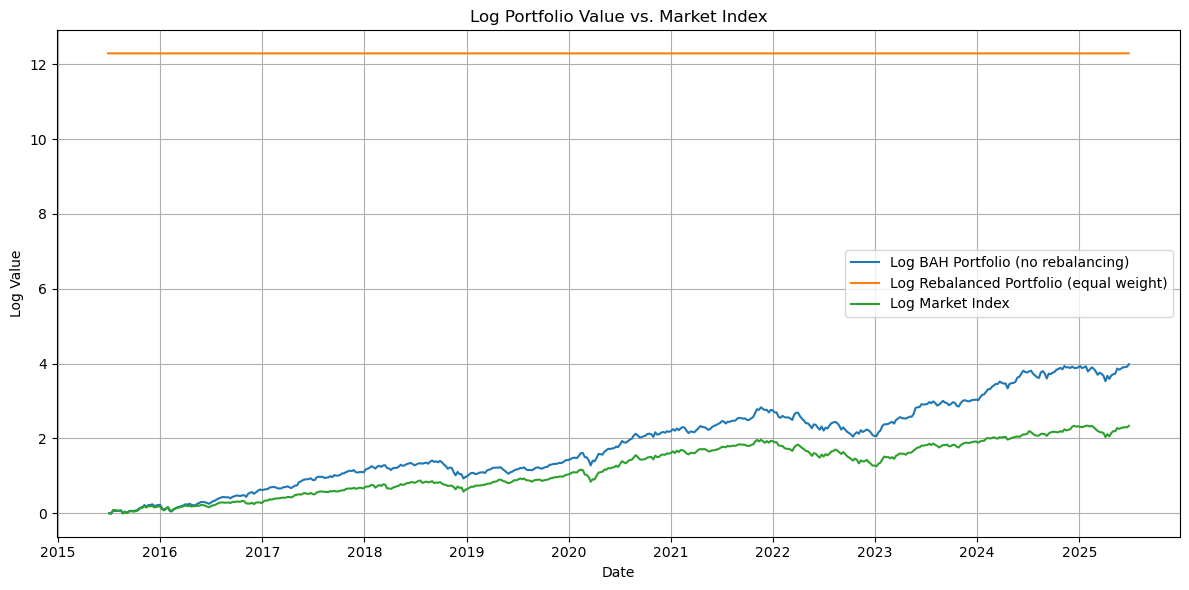

In [13]:
# 7. Plot all three log values
plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio), label="Log Rebalanced Portfolio (equal weight)")
plt.plot(np.log(market_index), label="Log Market Index")
plt.title("Log Portfolio Value vs. Market Index")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
print(weekly_returns.head())
print(weekly_returns.tail())

Ticker          AAPL      AMZN     GOOGL      META      MSFT      NVDA  \
Date                                                                     
2015-07-03 -0.002446 -0.000890 -0.010342 -0.008181 -0.019001 -0.015429   
2015-07-10 -0.024992  0.013251  0.016023  0.007561  0.004730 -0.032811   
2015-07-17  0.051428  0.089062  0.258060  0.079818  0.045057  0.016203   
2015-07-24 -0.039500  0.096085 -0.064106  0.020849 -0.014587 -0.032387   
2015-07-31 -0.025703  0.012712  0.004169 -0.030325  0.016544  0.027292   

Ticker          TSLA  
Date                  
2015-07-03  0.048411  
2015-07-10 -0.074530  
2015-07-17  0.059850  
2015-07-24 -0.033678  
2015-07-31  0.002788  
Ticker          AAPL      AMZN     GOOGL      META      MSFT      NVDA  \
Date                                                                     
2025-05-30  0.028576  0.020001  0.019410  0.032581  0.022613  0.029248   
2025-06-06  0.015285  0.041754  0.011296  0.077561  0.021766  0.048768   
2025-06-13 -0.036632 -0.

In [12]:
print(rebalanced_values)

[10000, -11.255387168854128, 0.1459498026153072, 0.01249910361509263, -0.00012021246690212515, -1.284068897363548e-07, -1.6331430714088684e-10, -2.1529263830765694e-12, 1.6133562061447282e-13, 8.205910004464733e-15, -2.9131491330754936e-16, -1.1951275188757037e-17, -2.0082292972421112e-19, 1.6391656541525988e-21, 1.1232851170785671e-23, 6.454491532832247e-26, 2.171497718388547e-27, 8.196547034237731e-29, 5.733001304952597e-31, 3.540554975148227e-32, -1.806635027091085e-33, -8.687339007968057e-35, -2.3250595024759984e-37, -4.395109045736022e-39, 1.8901945633250324e-40, 1.461490856094728e-42, 2.069100465632347e-44, 1.1168751457258632e-46, -9.412980278141069e-48, 3.3659111722607897e-49, 1.1234010260100535e-50, 2.216267911771988e-52, -2.084396586056788e-53, 2.8767414622247974e-55, 1.819533767460435e-56, 6.660659893013726e-58, 2.0191733223332123e-59, 1.5737914007364473e-61, 4.872291935750278e-63, 5.498300446216974e-65, 1.8109458471166032e-66, -1.5617683829085525e-68, -3.6420074645437787e-70

In [14]:
help(yf.download)

Help on function download in module yfinance.multi:

download(tickers, start=None, end=None, actions=False, threads=True, ignore_tz=None, group_by='column', auto_adjust=None, back_adjust=False, repair=False, keepna=False, progress=True, period='max', interval='1d', prepost=False, proxy=<object object at 0x138404670>, rounding=False, timeout=10, session=None, multi_level_index=True) -> Optional[pandas.core.frame.DataFrame]
    Download yahoo tickers
    :Parameters:
        tickers : str, list
            List of tickers to download
        period : str
            Valid periods: 1d,5d,1mo,3mo,6mo,1y,2y,5y,10y,ytd,max
            Either Use period parameter or use start and end
        interval : str
            Valid intervals: 1m,2m,5m,15m,30m,60m,90m,1h,1d,5d,1wk,1mo,3mo
            Intraday data cannot extend last 60 days
        start: str
            Download start date string (YYYY-MM-DD) or _datetime, inclusive.
            Default is 99 years ago
            E.g. for start="202